In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Imports successful!")
print("PyTorch version:", torch.__version__)


Imports successful!
PyTorch version: 2.11.0+cpu


In [2]:
# Start clean: remove output folders from earlier runs
!rm -rf /kaggle/working/runs_rf /kaggle/working/runs_rf_v2 /kaggle/working/runs_smoke

In [3]:

mnist_train = datasets.MNIST(
    root="/kaggle/working/data",
    train=True,
    download=True
)

mnist_test = datasets.MNIST(
    root="/kaggle/working/data",
    train=False,
    download=True
)

# Convert images and labels into NumPy arrays
train_x_all = mnist_train.data.numpy()
train_y_all = mnist_train.targets.numpy()

test_x = mnist_test.data.numpy()
test_y = mnist_test.targets.numpy()

# Binary labels: even = 0, odd = 1
train_y_all = (train_y_all % 2).astype(np.int64)
test_y = (test_y % 2).astype(np.int64)

# Split training data into train and validation sets
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(train_x_all))

split = int(0.8 * len(indices))
train_idx = indices[:split]
val_idx = indices[split:]

train_x = train_x_all[train_idx]
train_y = train_y_all[train_idx]

val_x = train_x_all[val_idx]
val_y = train_y_all[val_idx]

print("Training examples:", len(train_x))
print("Validation examples:", len(val_x))
print("Test examples:", len(test_x))
print("Binary classes:", np.unique(train_y))


100%|██████████| 9.91M/9.91M [00:00<00:00, 59.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.76MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 12.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.11MB/s]

Training examples: 48000
Validation examples: 12000
Test examples: 10000
Binary classes: [0 1]


In [4]:

def make_colored_mnist(images, labels, corr, seed=42):
    if not -1 <= corr <= 1:
        raise ValueError("corr must be between -1 and 1")

    rng = np.random.default_rng(seed)

    # Choose whether color agrees with the label
    matches = rng.random(len(labels)) < ((1 + corr) / 2)

    # Color bit: 0 = red, 1 = green
    color_bits = np.where(matches, labels, 1 - labels).astype(np.int64)

    # Normalize grayscale images to [0, 1]
    grayscale = images.astype(np.float32) / 255.0

    # Build RGB images: one active color channel
    colored = np.zeros(
        (len(images), 3, 28, 28),
        dtype=np.float32
    )

    red_mask = (color_bits == 0)
    green_mask = (color_bits == 1)

    colored[red_mask, 0, :, :] = grayscale[red_mask]
    colored[green_mask, 1, :, :] = grayscale[green_mask]

    return colored, color_bits

print("Colored MNIST generator defined!")


Colored MNIST generator defined!


In [5]:

train_images, train_colors = make_colored_mnist(
    train_x, train_y, corr=0.95, seed=101
)

val_images, val_colors = make_colored_mnist(
    val_x, val_y, corr=0.95, seed=102
)

train_labels = train_y
val_labels = val_y

print("Training image shape:", train_images.shape)
print("Validation image shape:", val_images.shape)
print("Training labels shape:", train_labels.shape)
print("Training colors shape:", train_colors.shape)


Training image shape: (48000, 3, 28, 28)
Validation image shape: (12000, 3, 28, 28)
Training labels shape: (48000,)
Training colors shape: (48000,)


In [6]:

test_correlations = [0.75, 0.50, 0.25, 0.00, -0.95]

ood_data = {}

for i, corr in enumerate(test_correlations):
    images, colors = make_colored_mnist(
        test_x,
        test_y,
        corr=corr,
        seed=200 + i
    )

    ood_data[corr] = (images, test_y.copy(), colors)

print("Test environments created:", list(ood_data.keys()))


Test environments created: [0.75, 0.5, 0.25, 0.0, -0.95]


In [7]:
def show_correlation(name, labels, colors):
    agreement = np.mean(labels == colors)
    observed_corr = np.corrcoef(labels, colors)[0, 1]

    print(f"{name}")
    print(f"  Color-label agreement: {agreement:.3f}")
    print(f"  Observed correlation:  {observed_corr:.3f}")

show_correlation("Training", train_labels, train_colors)

for corr, (_, labels, colors) in ood_data.items():
    show_correlation(f"Test target correlation = {corr}", labels, colors)

assert train_images.shape == (len(train_labels), 3, 28, 28)
assert train_images.dtype == np.float32
assert train_images.min() >= 0.0
assert train_images.max() <= 1.0

print("\nBasic data checks passed!")


Training
  Color-label agreement: 0.975
  Observed correlation:  0.950
Test target correlation = 0.75
  Color-label agreement: 0.882
  Observed correlation:  0.764
Test target correlation = 0.5
  Color-label agreement: 0.753
  Observed correlation:  0.506
Test target correlation = 0.25
  Color-label agreement: 0.620
  Observed correlation:  0.240
Test target correlation = 0.0
  Color-label agreement: 0.500
  Observed correlation:  0.001
Test target correlation = -0.95
  Color-label agreement: 0.025
  Observed correlation:  -0.950

Basic data checks passed!


In [8]:

def swap_red_green(images):
    swapped = images.copy()
    swapped[:, [0, 1], :, :] = images[:, [1, 0], :, :]
    return swapped

# Test on a small batch
sample = train_images[:100]
counterfactual = swap_red_green(sample)
recovered = swap_red_green(counterfactual)

print("Exact recovery:", np.array_equal(recovered, sample))

original_intensity = sample.sum(axis=1)
counterfactual_intensity = counterfactual.sum(axis=1)

print(
    "Per-pixel intensity preserved:",
    np.allclose(original_intensity, counterfactual_intensity)
)

print("Labels unchanged by intervention:", len(train_labels[:100]) == len(counterfactual))


Exact recovery: True
Per-pixel intensity preserved: True
Labels unchanged by intervention: True


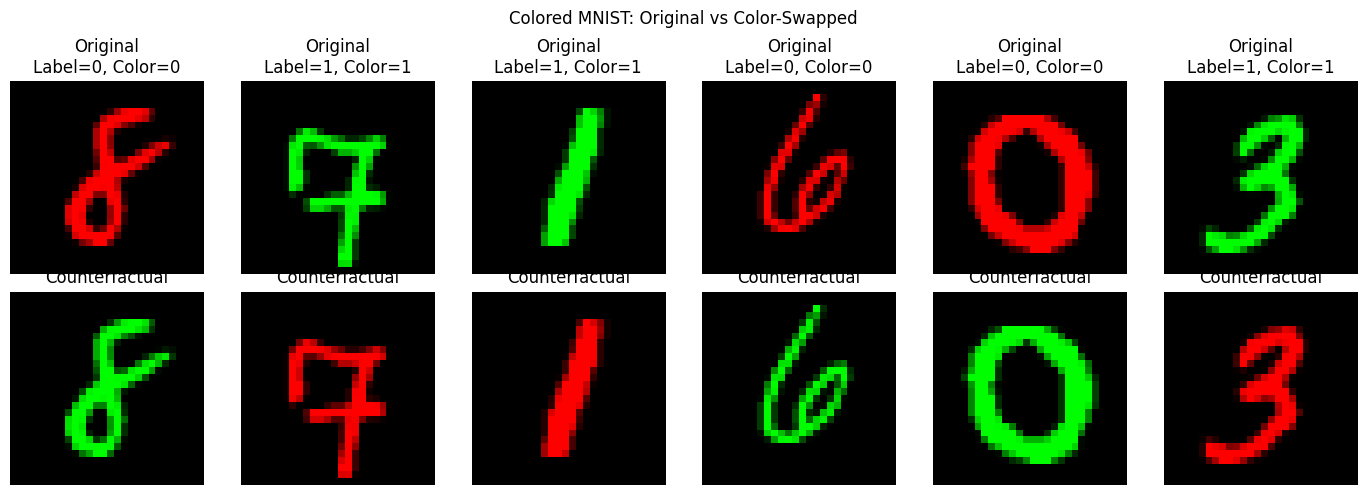

In [9]:

fig, axes = plt.subplots(2, 6, figsize=(14, 5))

for i in range(6):
    original = train_images[i]
    counterfactual = swap_red_green(original[None, ...])[0]

    axes[0, i].imshow(np.transpose(original, (1, 2, 0)))
    axes[0, i].set_title(
        f"Original\nLabel={train_labels[i]}, Color={train_colors[i]}"
    )

    axes[1, i].imshow(np.transpose(counterfactual, (1, 2, 0)))
    axes[1, i].set_title("Counterfactual")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.suptitle("Colored MNIST: Original vs Color-Swapped")
plt.tight_layout()
plt.show()


In [10]:

print("========== PART 1 + PART 2 CHECKPOINT ==========")
print("Training data:", train_images.shape)
print("Validation data:", val_images.shape)
print("Test environments:", len(ood_data))
print("Intervention reversibility:", np.array_equal(
    swap_red_green(swap_red_green(train_images[:10])),
    train_images[:10]
))
print("Ready for baseline modelling!")


========== PART 1 + PART 2 CHECKPOINT ==========
Training data: (48000, 3, 28, 28)
Validation data: (12000, 3, 28, 28)
Test environments: 5
Intervention reversibility: True
Ready for baseline modelling!


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# Flatten each image into a vector of 2,352 pixel features
X_train = train_images.reshape(len(train_images), -1)
X_val = val_images.reshape(len(val_images), -1)

# Train a simple baseline model
baseline = LogisticRegression(
    max_iter=300,
    solver="lbfgs"
)

baseline.fit(X_train, train_labels)

val_predictions = baseline.predict(X_val)
val_accuracy = accuracy_score(val_labels, val_predictions)

print(f"Validation accuracy: {val_accuracy:.4f}")

Validation accuracy: 0.9807


In [12]:
results = []

for corr, (images, labels, colors) in ood_data.items():
    X_test_env = images.reshape(len(images), -1)

    predictions = baseline.predict(X_test_env)
    accuracy = accuracy_score(labels, predictions)

    results.append({
        "Target correlation": corr,
        "Accuracy": accuracy
    })

for result in results:
    print(
        f"Target correlation: {result['Target correlation']:>5} | "
        f"Accuracy: {result['Accuracy']:.4f}"
    )

Target correlation:  0.75 | Accuracy: 0.9335
Target correlation:   0.5 | Accuracy: 0.8678
Target correlation:  0.25 | Accuracy: 0.7991
Target correlation:   0.0 | Accuracy: 0.7353
Target correlation: -0.95 | Accuracy: 0.4839


In [13]:
sample_images = test_x[:2000]
sample_labels = test_y[:2000]

# Create a test set with the training color relationship
sample_colored, sample_colors = make_colored_mnist(
    sample_images,
    sample_labels,
    corr=0.95,
    seed=777
)

sample_counterfactual = swap_red_green(sample_colored)

original_predictions = baseline.predict(
    sample_colored.reshape(len(sample_colored), -1)
)

counterfactual_predictions = baseline.predict(
    sample_counterfactual.reshape(len(sample_counterfactual), -1)
)

prediction_change_rate = np.mean(
    original_predictions != counterfactual_predictions
)

original_accuracy = accuracy_score(sample_labels, original_predictions)
counterfactual_accuracy = accuracy_score(
    sample_labels, counterfactual_predictions
)

print(f"Original accuracy: {original_accuracy:.4f}")
print(f"Counterfactual accuracy: {counterfactual_accuracy:.4f}")
print(f"Prediction change rate: {prediction_change_rate:.4f}")

Original accuracy: 0.9870
Counterfactual accuracy: 0.4815
Prediction change rate: 0.5265


In [14]:

# Model A: RGB images, including color and shape
X_rgb_train = train_images.reshape(len(train_images), -1)
X_rgb_val = val_images.reshape(len(val_images), -1)

# Model B: Color-only features
# The red and green channels are mutually exclusive in our generator.
# Mean red and green intensity identify the assigned color.
X_color_train = train_images[:, :2, :, :].mean(axis=(2, 3))
X_color_val = val_images[:, :2, :, :].mean(axis=(2, 3))

# Model C: Shape-only features
# Sum the RGB channels to recover the original grayscale digit.
X_shape_train = train_images.sum(axis=1).reshape(len(train_images), -1)
X_shape_val = val_images.sum(axis=1).reshape(len(val_images), -1)

print("RGB features:", X_rgb_train.shape)
print("Color-only features:", X_color_train.shape)
print("Shape-only features:", X_shape_train.shape)


RGB features: (48000, 2352)
Color-only features: (48000, 2)
Shape-only features: (48000, 784)


In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

models = {
    "RGB": LogisticRegression(max_iter=300),
    "Color-only": LogisticRegression(max_iter=300),
    "Shape-only": LogisticRegression(max_iter=300)
}

feature_sets = {
    "RGB": (X_rgb_train, X_rgb_val),
    "Color-only": (X_color_train, X_color_val),
    "Shape-only": (X_shape_train, X_shape_val)
}

for name, model in models.items():
    X_train_model, X_val_model = feature_sets[name]

    model.fit(X_train_model, train_labels)

    val_predictions = model.predict(X_val_model)
    accuracy = accuracy_score(val_labels, val_predictions)

    print(f"{name:12s} validation accuracy: {accuracy:.4f}")


RGB          validation accuracy: 0.9807
Color-only   validation accuracy: 0.9739
Shape-only   validation accuracy: 0.8975


In [16]:

from sklearn.metrics import accuracy_score

ood_results = []

for corr, (images, labels, colors) in ood_data.items():

    # RGB representation
    X_rgb = images.reshape(len(images), -1)

    # Color-only representation
    X_color = images[:, :2, :, :].mean(axis=(2, 3))

    # Shape-only representation
    X_shape = images.sum(axis=1).reshape(len(images), -1)

    test_features = {
        "RGB": X_rgb,
        "Color-only": X_color,
        "Shape-only": X_shape
    }

    row = {"Target correlation": corr}

    for name, model in models.items():
        predictions = model.predict(test_features[name])
        row[name] = accuracy_score(labels, predictions)

    ood_results.append(row)

for row in ood_results:
    print(
        f"corr={row['Target correlation']:>5}: "
        f"RGB={row['RGB']:.4f}, "
        f"Color-only={row['Color-only']:.4f}, "
        f"Shape-only={row['Shape-only']:.4f}"
    )


corr= 0.75: RGB=0.9335, Color-only=0.8827, Shape-only=0.9008
corr=  0.5: RGB=0.8678, Color-only=0.7539, Shape-only=0.9008
corr= 0.25: RGB=0.7991, Color-only=0.6208, Shape-only=0.9008
corr=  0.0: RGB=0.7353, Color-only=0.5022, Shape-only=0.9008
corr=-0.95: RGB=0.4839, Color-only=0.0283, Shape-only=0.9008


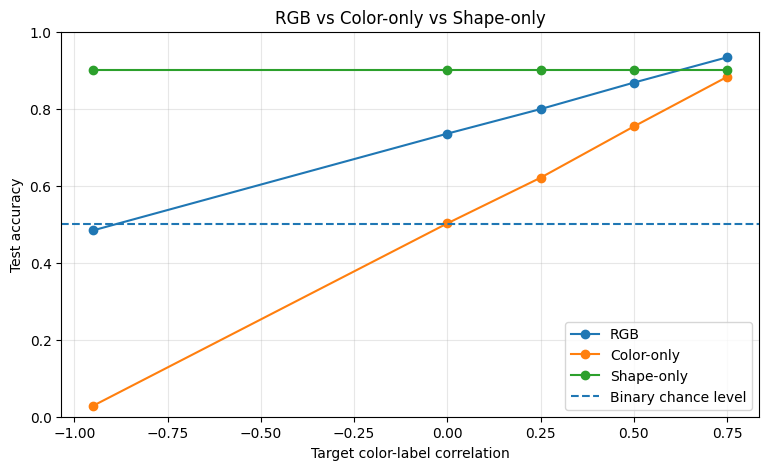

In [17]:

import matplotlib.pyplot as plt

correlations = [row["Target correlation"] for row in ood_results]

plt.figure(figsize=(9, 5))

for name in ["RGB", "Color-only", "Shape-only"]:
    accuracies = [row[name] for row in ood_results]
    plt.plot(correlations, accuracies, marker="o", label=name)

plt.axhline(0.5, linestyle="--", label="Binary chance level")
plt.xlabel("Target color-label correlation")
plt.ylabel("Test accuracy")
plt.title("RGB vs Color-only vs Shape-only")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [18]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Use only the color identity, not the image pixels
X_color_train_strict = train_colors.reshape(-1, 1)
X_color_val_strict = val_colors.reshape(-1, 1)

strict_color_model = LogisticRegression()
strict_color_model.fit(X_color_train_strict, train_labels)

val_pred = strict_color_model.predict(X_color_val_strict)

print(
    "Strict color-only validation accuracy:",
    round(accuracy_score(val_labels, val_pred), 4)
)


Strict color-only validation accuracy: 0.9738


In [19]:

strict_color_results = []

for corr, (images, labels, colors) in ood_data.items():
    predictions = strict_color_model.predict(colors.reshape(-1, 1))
    accuracy = accuracy_score(labels, predictions)

    strict_color_results.append({
        "correlation": corr,
        "accuracy": accuracy
    })

for result in strict_color_results:
    print(
        f"corr={result['correlation']:>5}: "
        f"strict color-only accuracy={result['accuracy']:.4f}"
    )


corr= 0.75: strict color-only accuracy=0.8822
corr=  0.5: strict color-only accuracy=0.7532
corr= 0.25: strict color-only accuracy=0.6197
corr=  0.0: strict color-only accuracy=0.5005
corr=-0.95: strict color-only accuracy=0.0252


In [20]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from itertools import combinations
from math import factorial
import pandas as pd

ATTRS = ["color", "marker_tl", "marker_br"]
PATCH = {"marker_tl": (slice(1, 4), slice(1, 4)),     # top-left 3x3
         "marker_br": (slice(24, 27), slice(24, 27))} # bottom-right 3x3

def make_multi_attr_mnist(images, labels, corrs, seed=0):
    """corrs: dict attr -> label correlation (0 = independent decoy)."""
    rng = np.random.default_rng(seed)
    gray = images.astype(np.float32) / 255.0
    n = len(labels)
    out = np.zeros((n, 3, 28, 28), dtype=np.float32)
    attrs = {}
    for a in ATTRS:
        c = corrs.get(a, 0.0)
        match = rng.random(n) < (1 + c) / 2
        attrs[a] = np.where(match, labels, 1 - labels).astype(np.int64)
    out[attrs["color"] == 0, 0] = gray[attrs["color"] == 0]   # red
    out[attrs["color"] == 1, 1] = gray[attrs["color"] == 1]   # green
    for a, (r, c) in PATCH.items():                           # markers: blue channel only
        out[attrs[a] == 1, 2, r, c] = 1.0
    return out, attrs

In [21]:
def intervene(images, attr):
    x = images.copy()
    if attr == "color":
        x[:, [0, 1]] = images[:, [1, 0]]                 # swap red/green
    elif attr in PATCH:
        r, c = PATCH[attr]
        x[:, 2, r, c] = 1.0 - images[:, 2, r, c]         # toggle marker on/off
    elif attr == "null":
        pass                                             # do-nothing control
    else:
        raise ValueError(attr)
    return x

In [22]:
def build_registry(labels, attrs, threshold=0.5):
    reg = {}
    for a, v in attrs.items():
        corr = float(np.corrcoef(labels, v)[0, 1])
        reg[a] = {"train_corr": corr, "spurious": abs(corr) >= threshold}
    return reg

flat = lambda x: x.reshape(len(x), -1)

In [23]:
def sensitivity_score(model, X, attr):
    """Main score (Person 2's job): fraction of predictions that flip."""
    p0 = model.predict(flat(X))
    p1 = model.predict(flat(intervene(X, attr)))
    return float(np.mean(p0 != p1))

def label_corr_score(labels, attrs, attr):
    """Data-only baseline."""
    return abs(float(np.corrcoef(labels, attrs[attr])[0, 1]))

In [24]:
def stability_score(model, X, y, attrs, attr):
    pred = model.predict(flat(X))
    agree = attrs[attr] == y
    if agree.sum() < 20 or (~agree).sum() < 20:
        return np.nan                     # too few samples in one group
    return float(accuracy_score(y[agree], pred[agree])
                 - accuracy_score(y[~agree], pred[~agree]))

In [25]:
def attribute_shapley(model, X, y, attr_list):
    k = len(attr_list)
    def value(S):
        x = X
        for a in S:
            x = intervene(x, a)
        proba = model.predict_proba(flat(x))
        return proba[np.arange(len(y)), y]          # P(true class)
    cache = {frozenset(S): value(S)
             for r in range(k + 1) for S in combinations(attr_list, r)}
    phi = {}
    for a in attr_list:
        others = [b for b in attr_list if b != a]
        tot = np.zeros(len(y))
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for S in combinations(others, r):
                tot += w * (cache[frozenset(S)] - cache[frozenset(S) | {a}])
        phi[a] = float(np.mean(np.abs(tot)))
    return phi

In [26]:
def run_task(task_id, model_fn, n_score=2000):
    rng = np.random.default_rng(1000 + task_id)
    order = rng.permutation(ATTRS)
    corrs = {order[0]: 0.9, order[1]: 0.6, order[2]: 0.0}   # strong, weak, decoy

    Xtr, Atr = make_multi_attr_mnist(train_x, train_y, corrs, seed=2000 + task_id)
    Xva, Ava = make_multi_attr_mnist(val_x,   val_y,   corrs, seed=3000 + task_id)
    reg = build_registry(train_y, Atr)

    model = model_fn().fit(flat(Xtr), train_y)
    Xs, ys = Xva[:n_score], val_y[:n_score]
    As = {a: v[:n_score] for a, v in Ava.items()}
    shap = attribute_shapley(model, Xs, ys, ATTRS)

    rows = []
    for a in ATTRS:
        rows.append({
            "task": task_id, "attr": a, "true_corr": corrs[a],
            "spurious": reg[a]["spurious"],
            "sensitivity": sensitivity_score(model, Xs, a),
            "label_corr":  label_corr_score(train_y, Atr, a),
            "stability":   stability_score(model, Xs, ys, As, a),
            "shap":        shap[a],
        })
    null = sensitivity_score(model, Xs, "null")
    return rows, order[0], null

def evaluate(all_rows, strongest,
             methods=("sensitivity", "label_corr", "stability", "shap")):
    df = pd.DataFrame(all_rows)
    out = {}
    for m in methods:
        top1 = np.mean([df[df.task == t].sort_values(m, ascending=False).attr.iloc[0] == s
                        for t, s in strongest.items()])
        sub = df.dropna(subset=[m])
        auroc = roc_auc_score(sub.spurious, sub[m]) if sub.spurious.nunique() == 2 else np.nan
        out[m] = {"top1": top1, "auroc": auroc}
    return df, pd.DataFrame(out).T

In [27]:
lr = lambda: LogisticRegression(max_iter=300)
rows, strongest = [], {}
for t in range(10):                      # more tasks = more credible
    r, s, null = run_task(t, lr)
    rows += r; strongest[t] = s
    print(f"task {t}: shortcut = {s}, null sensitivity = {null:.3f}")

df, summary = evaluate(rows, strongest)
print(summary)
df.to_csv("/kaggle/working/blind_detection_lr.csv", index=False)

task 0: shortcut = color, null sensitivity = 0.000
task 1: shortcut = marker_br, null sensitivity = 0.000
task 2: shortcut = color, null sensitivity = 0.000
task 3: shortcut = marker_br, null sensitivity = 0.000
task 4: shortcut = color, null sensitivity = 0.000
task 5: shortcut = color, null sensitivity = 0.000
task 6: shortcut = marker_br, null sensitivity = 0.000
task 7: shortcut = marker_br, null sensitivity = 0.000
task 8: shortcut = marker_tl, null sensitivity = 0.000
task 9: shortcut = marker_br, null sensitivity = 0.000
             top1  auroc
sensitivity   1.0    1.0
label_corr    1.0    1.0
stability     1.0    1.0
shap          1.0    1.0


In [28]:
#  CONFIG 
import os, json, time, hashlib, itertools, pickle, shutil, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, t as t_dist
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./working")

CONFIG = {
    "out_dir": f"{WORK}/runs_rf",                # CHANGED (was runs_rf_v2)
    # ---- experiment grid (cut down to what the team can finish) ----
    "grid": {
        "arch":       ["lr"],                    # Stage B: add "rf", "mlp", "cnn"
        "train_corr": [0.5, 0.7, 0.85, 0.95],
        "size":       [5000, 20000],
        "seed":       [0, 1, 2, 3, 4],
        "reg":        ["default"],               # stretch: ["low", "default", "high"]
        "aug":        ["none"],                  # stretch: ["none", "color_rand"]
    },
    "shortcut":    "color",                      # attribute whose correlation is swept
    "decoy_corrs": {"marker_tl": 0.0, "marker_br": 0.0},   # label-independent decoys
    "aug_p":       0.5,                          # fraction of train images colour-swapped under "color_rand"
    # ---- OOD environments (colour-label correlation at test time) ----
    "ood_envs":    {"E2": 0.75, "E3": 0.50, "E4": 0.25, "E5": 0.00, "REV": -0.95},
    # ---- scoring ----
    "n_score":     2000,                         # held-out val samples used for scoring
    "spurious_threshold": 0.5,
    "methods":     ["sensitivity", "label_corr", "stability", "shap"],
    # ---- analysis ----
    "target":      "rev_drop",                   # also: "mean_drop", "worst_drop"
    "cluster_by":  "seed",                       # cluster bootstrap unit
    "n_boot":      2000,
    "alpha":       0.05,
}

RESULT_COLS = ["run_id", "model", "seed", "size", "corr", "reg", "aug",
               "method", "feature", "score", "spurious"]

def read_scores(path):
    # keep the literal feature name "null" (pandas would otherwise read it as NaN)
    return pd.read_csv(path, keep_default_na=False, na_values=[""])

def paths(cfg):
    d = cfg["out_dir"]
    return {
        "dir": d,
        "models":   f"{d}/models",
        "partial":  f"{d}/partial",
        "meta":     f"{d}/run_meta.csv",
        "frozen":   f"{d}/scores_frozen.csv",
        "manifest": f"{d}/scores_frozen.manifest.json",
        "ood_long": f"{d}/ood_drops_long.csv",
        "ood_wide": f"{d}/ood_drops.csv",
        "analysis": f"{d}/analysis_spearman.csv",
    }

def grid_runs(cfg):
    g = cfg["grid"]
    keys = ["arch", "train_corr", "size", "seed", "reg", "aug"]
    return [dict(zip(keys, v)) for v in itertools.product(*[g[k] for k in keys])]

def run_id_of(r):
    return f"{r['arch']}_c{r['train_corr']}_n{r['size']}_s{r['seed']}_r{r['reg']}_a{r['aug']}"

print(f"Output dir: {CONFIG['out_dir']}")
print(f"Grid size:  {len(grid_runs(CONFIG))} runs")

# RANDOM FOREST CONFIGURATION
CONFIG["grid"]["arch"] = ["rf"]
CONFIG["out_dir"] = f"{WORK}/runs_rf"            # CHANGED (was runs_rf_v2)

print("Architecture:", CONFIG["grid"]["arch"])
print("Output directory:", CONFIG["out_dir"])
print("Total runs:", len(grid_runs(CONFIG)))

Output dir: /kaggle/working/runs_rf
Grid size:  40 runs
Architecture: ['rf']
Output directory: /kaggle/working/runs_rf
Total runs: 40


In [29]:
# MODEL FACTORY 
# All models take FLAT inputs (N, 3*28*28) because the shared score functions call
# model.predict(flat(X)). A CNN wrapper (Stage B) must reshape inside and have
# fit / predict / predict_proba, then be added to MODEL_REGISTRY.
MODEL_REGISTRY = {}

REG_LEVELS = {
    "lr":  {"low": 10.0, "default": 1.0,  "high": 0.01},   # C
    "rf":  {"low": None, "default": 12,   "high": 6},      # max_depth
    "mlp": {"low": 1e-5, "default": 1e-4, "high": 1e-2},   # L2 alpha
}

def make_model(arch, reg="default", seed=0):
    if arch in MODEL_REGISTRY:
        return MODEL_REGISTRY[arch](reg=reg, seed=seed)
    if arch == "lr":
        return LogisticRegression(C=REG_LEVELS["lr"][reg], max_iter=300)
    if arch == "rf":
        return RandomForestClassifier(n_estimators=200, max_depth=REG_LEVELS["rf"][reg],
                                      n_jobs=-1, random_state=seed)
    if arch == "mlp":
        return MLPClassifier(hidden_layer_sizes=(256,), alpha=REG_LEVELS["mlp"][reg],
                             max_iter=50, early_stopping=True, random_state=seed)
    raise ValueError(f"Unknown arch '{arch}'. Register it in MODEL_REGISTRY.")

In [30]:
# RUN DRIVER (pre-shift only: never touches test_x)
def _shap_cached(ctx, attr):
    if "_shap" not in ctx:
        ctx["_shap"] = attribute_shapley(ctx["model"], ctx["Xs"], ctx["ys"], ATTRS)
    return ctx["_shap"][attr]

# Every score method has the same shape: fn(ctx, attr) -> number.
# To add a new method (e.g. mutual information), just add it here.
SCORE_FNS = {
    "sensitivity": lambda ctx, a: sensitivity_score(ctx["model"], ctx["Xs"], a),
    "label_corr":  lambda ctx, a: label_corr_score(ctx["ytr"], ctx["Atr"], a),
    "stability":   lambda ctx, a: stability_score(ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"], a),
    "shap":        _shap_cached,
}

def make_e1(cfg, train_corr, size, seed, aug):
    """Training environment E1 (+ held-out val). Uses train_x / val_x only."""
    corrs = {cfg["shortcut"]: train_corr, **cfg["decoy_corrs"]}
    rng = np.random.default_rng(10_000 + seed)
    idx = rng.choice(len(train_y), size=min(size, len(train_y)), replace=False)
    Xtr, Atr = make_multi_attr_mnist(train_x[idx], train_y[idx], corrs, seed=20_000 + seed)
    ytr = train_y[idx]

    if aug == "color_rand":                     # colour randomisation augmentation
        flip = np.random.default_rng(30_000 + seed).random(len(ytr)) < cfg["aug_p"]
        Xtr[flip] = intervene(Xtr[flip], "color")
        Atr["color"] = np.where(flip, 1 - Atr["color"], Atr["color"])
    elif aug != "none":
        raise ValueError(aug)

    Xva, Ava = make_multi_attr_mnist(val_x, val_y, corrs, seed=40_000 + seed)
    return Xtr, ytr, Atr, Xva, val_y, Ava

def run_one(cfg, r):
    P = paths(cfg)
    rid = run_id_of(r)
    Xtr, ytr, Atr, Xva, yva, Ava = make_e1(cfg, r["train_corr"], r["size"], r["seed"], r["aug"])
    reg = build_registry(ytr, Atr, threshold=cfg["spurious_threshold"])

    t0 = time.time()
    model = make_model(r["arch"], r["reg"], r["seed"]).fit(flat(Xtr), ytr)
    fit_s = time.time() - t0

    n = cfg["n_score"]
    ctx = {"model": model, "Xs": Xva[:n], "ys": yva[:n],
           "As": {a: v[:n] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}

    base = {"run_id": rid, "model": r["arch"], "seed": r["seed"], "size": r["size"],
            "corr": r["train_corr"], "reg": r["reg"], "aug": r["aug"]}
    rows = []
    for m in cfg["methods"]:
        for a in ATTRS:
            rows.append({**base, "method": m, "feature": a,
                         "score": SCORE_FNS[m](ctx, a), "spurious": reg[a]["spurious"]})
    # null control: a do-nothing intervention should score 0
    rows.append({**base, "method": "sensitivity", "feature": "null",
                 "score": sensitivity_score(model, ctx["Xs"], "null"), "spurious": False})

    meta = {**base,
            "train_acc": accuracy_score(ytr, model.predict(flat(Xtr))),
            "id_val_acc": accuracy_score(yva, model.predict(flat(Xva))),
            "fit_seconds": round(fit_s, 2),
            "model_path": f"{P['models']}/{rid}.pkl"}
    for a in ATTRS:
        meta[f"traincorr_{a}"] = reg[a]["train_corr"]

    with open(meta["model_path"], "wb") as f:
        pickle.dump(model, f)
    pd.DataFrame(rows, columns=RESULT_COLS).to_csv(f"{P['partial']}/{rid}.csv", index=False)
    pd.DataFrame([meta]).to_csv(f"{P['partial']}/{rid}.meta.csv", index=False)
    return rows, meta

def run_grid(cfg, shard=(0, 1), verbose=True):
    """Runs every grid setting not already done. shard=(i, k) runs every k-th one starting at i,
    so a long grid can be split across several Kaggle versions."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise RuntimeError("Scores are already frozen; start a new out_dir for a new grid.")
    os.makedirs(P["models"], exist_ok=True); os.makedirs(P["partial"], exist_ok=True)
    runs = grid_runs(cfg)[shard[0]::shard[1]]
    for i, r in enumerate(runs):
        rid = run_id_of(r)
        if os.path.exists(f"{P['partial']}/{rid}.csv"):
            if verbose: print(f"[{i+1}/{len(runs)}] skip (done) {rid}")
            continue
        t0 = time.time()
        rows, meta = run_one(cfg, r)
        if verbose:
            s = {(x["method"], x["feature"]): x["score"] for x in rows}
            print(f"[{i+1}/{len(runs)}] {rid}  id_acc={meta['id_val_acc']:.3f}  "
                  f"sens(color)={s[('sensitivity','color')]:.3f}  "
                  f"sens(null)={s[('sensitivity','null')]:.3f}  ({time.time()-t0:.1f}s)")

In [31]:
# FREEZE WRITER
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def freeze_scores(cfg):
    """Merge all score files into scores_frozen.csv. Refuses to overwrite."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise FileExistsError(f"{P['frozen']} is frozen and will not be overwritten.")
    expected = {run_id_of(r) for r in grid_runs(cfg)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    missing = expected - done
    if missing:
        raise RuntimeError(f"{len(missing)} runs missing, e.g. {sorted(missing)[:3]}. Finish the grid first.")

    scores = pd.concat([read_scores(f"{P['partial']}/{r}.csv") for r in sorted(expected)], ignore_index=True)
    meta = pd.concat([pd.read_csv(f"{P['partial']}/{r}.meta.csv") for r in sorted(expected)], ignore_index=True)
    assert list(scores.columns) == RESULT_COLS, "results schema drifted"

    scores.to_csv(P["frozen"], index=False)
    meta.to_csv(P["meta"], index=False)
    manifest = {"sha256": _sha256(P["frozen"]), "meta_sha256": _sha256(P["meta"]),
                "n_rows": len(scores), "n_runs": len(expected),
                "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "config": cfg}
    with open(P["manifest"], "w") as f:
        json.dump(manifest, f, indent=2, default=str)
    for p in (P["frozen"], P["meta"], P["manifest"]):
        os.chmod(p, 0o444)
    print(f"Frozen {len(scores)} score rows from {len(expected)} runs -> {P['frozen']}")
    print(f"sha256 = {manifest['sha256']}")
    return manifest

In [32]:
#  OOD EVALUATION
def verify_freeze(cfg):
    P = paths(cfg)
    if not (os.path.exists(P["frozen"]) and os.path.exists(P["manifest"])):
        raise RuntimeError("No frozen scores found. Run freeze_scores() before touching OOD data.")
    with open(P["manifest"]) as f:
        man = json.load(f)
    if _sha256(P["frozen"]) != man["sha256"] or _sha256(P["meta"]) != man["meta_sha256"]:
        raise RuntimeError("Frozen files were modified after freezing (hash mismatch).")
    return man

def ood_evaluate(cfg):
    P = paths(cfg)
    man = verify_freeze(cfg)
    meta = pd.read_csv(P["meta"])
    decoys = cfg["decoy_corrs"]

    # Same test images for every run, so drops are comparable
    env_cache = {}
    def env_data(c, seed):
        if c not in env_cache:
            X, _ = make_multi_attr_mnist(test_x, test_y, {cfg["shortcut"]: c, **decoys}, seed=seed)
            env_cache[c] = flat(X)
        return env_cache[c]

    rows = []
    for _, m in meta.iterrows():
        with open(m["model_path"], "rb") as f:
            model = pickle.load(f)
        # Baseline: test digits drawn with the run's own training correlation
        id_acc = accuracy_score(test_y, model.predict(env_data(m["corr"], 50_000)))
        for k, (env, c) in enumerate(cfg["ood_envs"].items()):
            acc = accuracy_score(test_y, model.predict(env_data(c, 60_000 + k)))
            rows.append({"run_id": m["run_id"], "model": m["model"], "seed": m["seed"],
                         "size": m["size"], "corr": m["corr"], "reg": m["reg"], "aug": m["aug"],
                         "env": env, "env_corr": c, "id_test_acc": id_acc,
                         "ood_acc": acc, "drop": id_acc - acc})
    long = pd.DataFrame(rows)

    keys = ["run_id", "model", "seed", "size", "corr", "reg", "aug", "id_test_acc"]
    wide = long.pivot_table(index=keys, columns="env", values="drop").add_suffix("_drop").reset_index()
    wide.columns.name = None
    std_envs = [f"{e}_drop" for e in cfg["ood_envs"] if e != "REV"]
    wide["mean_drop"] = wide[std_envs].mean(axis=1)
    wide["worst_drop"] = wide[[f"{e}_drop" for e in cfg["ood_envs"]]].max(axis=1)
    wide["rev_drop"] = wide["REV_drop"] if "REV_drop" in wide else np.nan
    wide["frozen_sha256"] = man["sha256"]

    long.to_csv(P["ood_long"], index=False)
    wide.to_csv(P["ood_wide"], index=False)
    print(f"OOD evaluation done for {len(meta)} runs -> {P['ood_wide']}")
    return long, wide

In [33]:
# ANALYSIS 
def _partial_spearman(x, y, z):
    """Spearman of x and y after removing the effect of z."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    Z = np.column_stack([np.ones_like(rz), rz])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    if ex.std() < 1e-12 or ey.std() < 1e-12:
        return np.nan, np.nan
    r = float(np.corrcoef(ex, ey)[0, 1])
    n = len(x); df = n - 3
    if df <= 0 or abs(r) >= 1:
        return r, np.nan
    tstat = r * np.sqrt(df / (1 - r * r))
    return r, float(2 * t_dist.sf(abs(tstat), df))

def _cluster_bootstrap_ci(df, xcol, ycol, cluster, n_boot, alpha, seed=0):
    rng = np.random.default_rng(seed)
    groups = {g: d for g, d in df.groupby(cluster)}
    keys = list(groups)
    stats = []
    for _ in range(n_boot):
        pick = rng.choice(keys, size=len(keys), replace=True)
        b = pd.concat([groups[k] for k in pick])
        if b[xcol].nunique() > 1 and b[ycol].nunique() > 1:
            stats.append(spearmanr(b[xcol], b[ycol])[0])
    if len(stats) < 10:
        return np.nan, np.nan
    return tuple(np.nanpercentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

def _holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(p[ok]); m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]).clip(max=1)
    tmp = np.empty(m); tmp[idx] = adj
    out[ok] = tmp
    return out

def load_analysis_table(cfg, feature=None):
    P = paths(cfg)
    verify_freeze(cfg)
    scores = read_scores(P["frozen"])
    ood = pd.read_csv(P["ood_wide"])
    feature = feature or cfg["shortcut"]
    wide = (scores[scores.feature == feature]
            .pivot_table(index="run_id", columns="method", values="score")
            .reset_index())
    wide.columns.name = None
    return scores, wide.merge(ood, on="run_id")

def analyze(cfg, target=None, feature=None, plot=True):
    target = target or cfg["target"]
    scores, df = load_analysis_table(cfg, feature)
    methods = [m for m in cfg["methods"] if m in df]

    # 1) Does each frozen score predict the later OOD drop?
    res = []
    for m in methods:
        d = df[list(dict.fromkeys([m, target, "label_corr", cfg["cluster_by"], "model"]))].dropna()
        if len(d) < 3 or d[m].nunique() < 2:
            res.append({"method": m, "n": len(d)}); continue
        rho, p = spearmanr(d[m], d[target])
        lo, hi = _cluster_bootstrap_ci(d, m, target, cfg["cluster_by"], cfg["n_boot"], cfg["alpha"])
        if m != "label_corr":
            prho, pp = _partial_spearman(d[m].values, d[target].values, d["label_corr"].values)
        else:
            prho, pp = np.nan, np.nan
        res.append({"method": m, "n": len(d), "spearman": rho, "ci_lo": lo, "ci_hi": hi,
                    "p": p, "partial_rho|label_corr": prho, "partial_p": pp})
    res = pd.DataFrame(res)
    if "p" in res:
        res["p_holm"] = _holm(res["p"].values)
        res["partial_p_holm"] = _holm(res["partial_p"].values)

    # 2) Grouped analysis (mixed-effects model)
    mixed = None
    try:
        import statsmodels.formula.api as smf
        warnings.filterwarnings("ignore", module="statsmodels")
        grp = "model" if df["model"].nunique() > 1 else cfg["cluster_by"]
        d = df.dropna(subset=["sensitivity", "label_corr", target]).copy()
        for c in ["sensitivity", "label_corr"]:
            d[c + "_z"] = (d[c] - d[c].mean()) / (d[c].std() + 1e-12)
        fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
        mixed = fit.summary().tables[1]
    except Exception as e:
        print(f"(mixed-effects model skipped: {type(e).__name__}: {e})")

    # 3) Null / decoy controls: colour should clearly beat both
    sens = (scores[scores.method == "sensitivity"]
            .pivot_table(index=["run_id", "corr"], columns="feature", values="score").reset_index())
    decoy_cols = [a for a in ATTRS if a != cfg["shortcut"]]
    sens["shortcut_beats_controls"] = sens[cfg["shortcut"]] > sens[decoy_cols + ["null"]].max(axis=1)
    controls = (sens.groupby("corr")[[cfg["shortcut"], *decoy_cols, "null", "shortcut_beats_controls"]]
                .mean().round(4))

    # 4) Blind detection on the grid (reuses Person 3's evaluate())
    bd = (scores[scores.feature.isin(ATTRS)]
          .pivot_table(index=["run_id", "feature"], columns="method", values="score").reset_index()
          .merge(scores[["run_id", "feature", "spurious"]].drop_duplicates(), on=["run_id", "feature"])
          .rename(columns={"run_id": "task", "feature": "attr"}))
    strongest = {t: cfg["shortcut"] for t in bd.task.unique()
                 if bd[(bd.task == t) & (bd.attr == cfg["shortcut"])].spurious.iloc[0]}
    _, blind = evaluate(bd[bd.task.isin(strongest)], strongest, methods=tuple(methods))

    print(f"\n=== Score vs {target} (feature = {feature or cfg['shortcut']}) ===")
    print(res.round(4).to_string(index=False))
    if mixed is not None:
        print("\n=== Mixed-effects model ===\n", mixed)
    print("\n=== Sensitivity controls (mean per training corr) ===\n", controls.to_string())
    print("\n=== Blind detection on grid runs ===\n", blind.round(4).to_string())

    P = paths(cfg)
    res.to_csv(P["analysis"], index=False)

    if plot:
        fig, axes = plt.subplots(1, len(methods), figsize=(4.2 * len(methods), 3.8), squeeze=False)
        for ax, m in zip(axes[0], methods):
            sc = ax.scatter(df[m], df[target], c=df["corr"], cmap="viridis", s=28)
            r = res.set_index("method").loc[m]
            ax.set_title(f"{m}\nρ={r.get('spearman', np.nan):.2f}")
            ax.set_xlabel(f"frozen {m} score"); ax.set_ylabel(target)
            ax.grid(alpha=0.3)
        fig.colorbar(sc, ax=axes[0].tolist(), label="training corr")
        plt.show()
    return res, controls, blind, mixed

In [34]:
# SMOKE TEST 
def smoke_test():
    cfg = copy.deepcopy(CONFIG)
    cfg["out_dir"] = f"{WORK}/runs_smoke"
    cfg["grid"] = {"arch": ["lr"], "train_corr": [0.6, 0.95], "size": [1500],
                   "seed": [0, 1], "reg": ["default"], "aug": ["none"]}
    cfg["n_score"] = 300
    cfg["n_boot"] = 200
    if os.path.exists(cfg["out_dir"]):
        for root, _, files in os.walk(cfg["out_dir"]):
            for f in files: os.chmod(os.path.join(root, f), 0o644)
        shutil.rmtree(cfg["out_dir"])
    P = paths(cfg)

    # The test-time check must be blocked before freezing
    try:
        os.makedirs(P["dir"], exist_ok=True); ood_evaluate(cfg)
        raise AssertionError("OOD eval ran before freeze!")
    except RuntimeError:
        pass

    run_grid(cfg)
    freeze_scores(cfg)
    try:
        freeze_scores(cfg); raise AssertionError("freeze overwrote frozen scores!")
    except FileExistsError:
        pass

    scores = read_scores(P["frozen"])
    assert list(scores.columns) == RESULT_COLS
    assert scores.run_id.nunique() == len(grid_runs(cfg))
    s = scores[scores.method == "sensitivity"].set_index(["run_id", "feature"])["score"]
    hi = [r for r in scores.run_id.unique() if "_c0.95_" in r]
    for r in scores.run_id.unique():
        assert s[(r, "null")] == 0.0, "null intervention must not change predictions"
    for r in hi:
        assert s[(r, "color")] > max(s[(r, "marker_tl")], s[(r, "marker_br")]), "colour should beat decoys"

    long, wide = ood_evaluate(cfg)
    assert {"mean_drop", "rev_drop", "worst_drop"} <= set(wide.columns)
    assert (wide[wide["corr"] == 0.95]["rev_drop"] > 0).all(), "reversed colour should hurt a 0.95 model"

    res, controls, blind, _ = analyze(cfg, plot=False)
    assert len(res) == len(cfg["methods"])
    print("\n SMOKE TEST PASSED")
    return cfg

smoke_cfg = smoke_test()

[1/4] lr_c0.6_n1500_s0_rdefault_anone  id_acc=0.890  sens(color)=0.257  sens(null)=0.000  (1.2s)
[2/4] lr_c0.6_n1500_s1_rdefault_anone  id_acc=0.888  sens(color)=0.277  sens(null)=0.000  (1.1s)
[3/4] lr_c0.95_n1500_s0_rdefault_anone  id_acc=0.977  sens(color)=0.790  sens(null)=0.000  (0.7s)
[4/4] lr_c0.95_n1500_s1_rdefault_anone  id_acc=0.977  sens(color)=0.770  sens(null)=0.000  (0.8s)
Frozen 52 score rows from 4 runs -> /kaggle/working/runs_smoke/scores_frozen.csv
sha256 = 955a9347f8a3b4cf55613b33cbb67a0d945879bc4bdef158caa996153be5947d
OOD evaluation done for 4 runs -> /kaggle/working/runs_smoke/ood_drops.csv

=== Score vs rev_drop (feature = color) ===
     method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
sensitivity  4       0.8    0.8    1.0 0.2                     NaN        NaN     0.4             NaN
 label_corr  4       1.0    1.0    1.0 0.0                     NaN        NaN     0.0             NaN
  stability  2       NaN    N

/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)


In [35]:
# MAIN RUN 
run_grid(CONFIG)
freeze_scores(CONFIG)

[1/40] rf_c0.5_n5000_s0_rdefault_anone  id_acc=0.936  sens(color)=0.199  sens(null)=0.000  (4.7s)
[2/40] rf_c0.5_n5000_s1_rdefault_anone  id_acc=0.932  sens(color)=0.222  sens(null)=0.000  (4.5s)
[3/40] rf_c0.5_n5000_s2_rdefault_anone  id_acc=0.928  sens(color)=0.231  sens(null)=0.000  (4.6s)
[4/40] rf_c0.5_n5000_s3_rdefault_anone  id_acc=0.933  sens(color)=0.218  sens(null)=0.000  (4.6s)
[5/40] rf_c0.5_n5000_s4_rdefault_anone  id_acc=0.930  sens(color)=0.232  sens(null)=0.000  (4.6s)
[6/40] rf_c0.5_n20000_s0_rdefault_anone  id_acc=0.951  sens(color)=0.157  sens(null)=0.000  (15.5s)
[7/40] rf_c0.5_n20000_s1_rdefault_anone  id_acc=0.948  sens(color)=0.157  sens(null)=0.000  (15.5s)
[8/40] rf_c0.5_n20000_s2_rdefault_anone  id_acc=0.949  sens(color)=0.152  sens(null)=0.000  (15.4s)
[9/40] rf_c0.5_n20000_s3_rdefault_anone  id_acc=0.950  sens(color)=0.155  sens(null)=0.000  (15.5s)
[10/40] rf_c0.5_n20000_s4_rdefault_anone  id_acc=0.949  sens(color)=0.160  sens(null)=0.000  (15.4s)
[11/40] r

{'sha256': '6c90a636aabf87f0245acac200d37e804a25f7276c8ed5b0337a472d0ba4d917',
 'meta_sha256': '3fb87c9af0a8950d5b67c5f9c18d3a55f4b302c7ce8118924d4fa617c5571fd1',
 'n_rows': 520,
 'n_runs': 40,
 'frozen_at': '2026-11-07 19:28:40',
 'config': {'out_dir': '/kaggle/working/runs_rf',
  'grid': {'arch': ['rf'],
   'train_corr': [0.5, 0.7, 0.85, 0.95],
   'size': [5000, 20000],
   'seed': [0, 1, 2, 3, 4],
   'reg': ['default'],
   'aug': ['none']},
  'shortcut': 'color',
  'decoy_corrs': {'marker_tl': 0.0, 'marker_br': 0.0},
  'aug_p': 0.5,
  'ood_envs': {'E2': 0.75, 'E3': 0.5, 'E4': 0.25, 'E5': 0.0, 'REV': -0.95},
  'n_score': 2000,
  'spurious_threshold': 0.5,
  'methods': ['sensitivity', 'label_corr', 'stability', 'shap'],
  'target': 'rev_drop',
  'cluster_by': 'seed',
  'n_boot': 2000,
  'alpha': 0.05}}

OOD evaluation done for 40 runs -> /kaggle/working/runs_rf/ood_drops.csv


/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)



=== Score vs rev_drop (feature = color) ===
     method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
sensitivity 40    0.9992 0.9972 1.0000 0.0                  0.9923        0.0     0.0             0.0
 label_corr 40    0.9503 0.9098 0.9770 0.0                     NaN        NaN     0.0             NaN
  stability 40    0.9852 0.9816 0.9936 0.0                  0.8566        0.0     0.0             0.0
       shap 40    0.9972 0.9934 0.9987 0.0                  0.9715        0.0     0.0             0.0

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025  0.975]
Intercept       0.482    0.002  270.662  0.000   0.478   0.485
sensitivity_z   0.317    0.006   49.865  0.000   0.305   0.330
label_corr_z   -0.018    0.006   -2.847  0.004  -0.031  -0.006
Group Var       0.000                                         

=== Sensitivity controls (mean per training corr) ===
 feature   color  marker_tl  marker_br  null 

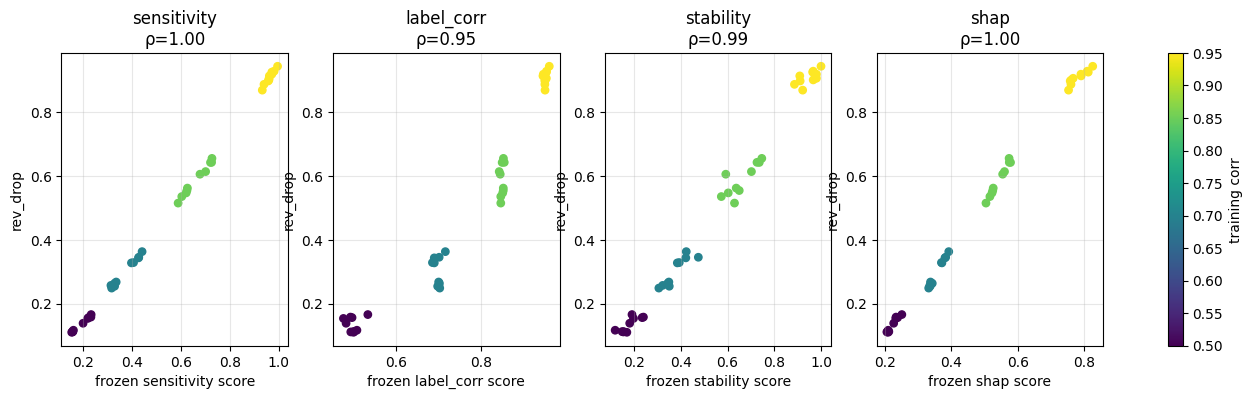

/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: Retrying MixedLM optimization with cg
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: Gradient optimization failed, |grad| = 1.333581
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/tmp/ipykernel_16/2326687402.py:86: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[gr


=== Score vs mean_drop (feature = color) ===
     method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
sensitivity 40    0.9964 0.9937 0.9995 0.0                  0.9657        0.0     0.0             0.0
 label_corr 40    0.9451 0.9070 0.9708 0.0                     NaN        NaN     0.0             NaN
  stability 40    0.9883 0.9846 0.9944 0.0                  0.8912        0.0     0.0             0.0
       shap 40    0.9941 0.9917 0.9972 0.0                  0.9439        0.0     0.0             0.0

=== Mixed-effects model ===
                 Coef. Std.Err.       z  P>|z|  [0.025  0.975]
Intercept       0.126    0.002  80.633  0.000   0.123   0.129
sensitivity_z   0.114    0.006  20.371  0.000   0.103   0.125
label_corr_z   -0.013    0.006  -2.352  0.019  -0.024  -0.002
Group Var       0.000                                        

=== Sensitivity controls (mean per training corr) ===
 feature   color  marker_tl  marker_br  null  sho

In [36]:
# OOD + ANALYSIS (only after the freeze) 
ood_long, ood_wide = ood_evaluate(CONFIG)
results, controls, blind, mixed = analyze(CONFIG, target="rev_drop")
_ = analyze(CONFIG, target="mean_drop", plot=False)

In [37]:
# Verify Random Forest configuration

rf_model = make_model("rf", reg="default", seed=42)

print(rf_model)
print("Number of trees:", rf_model.n_estimators)
print("Maximum tree depth:", rf_model.max_depth)
print("Model factory verification complete.")

RandomForestClassifier(max_depth=12, n_estimators=200, n_jobs=-1,
                       random_state=42)
Number of trees: 200
Maximum tree depth: 12
Model factory verification complete.


feature,color,marker_br,marker_tl
method,,,
label_corr,0.748931,0.008702,0.010825
sensitivity,0.545975,0.000675,0.000762
shap,0.476584,0.001716,0.001747
stability,0.540939,-0.005730,0.002772


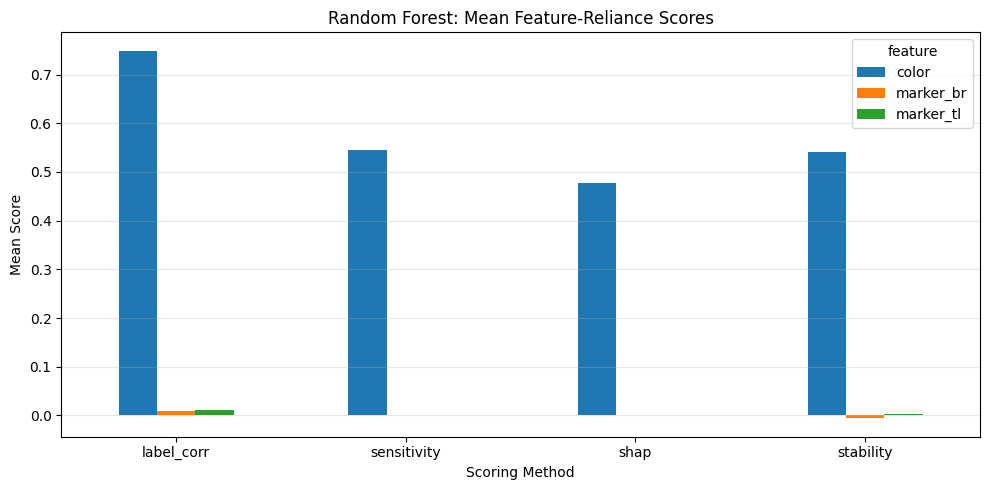

In [38]:
# Compare feature-reliance scores across runs

rf_scores = read_scores(paths(CONFIG)["frozen"])

feature_scores = rf_scores[
    (rf_scores["method"] != "sensitivity") |
    (rf_scores["feature"] != "null")
]

summary_rf = (
    feature_scores[
        feature_scores["method"].isin(CONFIG["methods"])
    ]
    .groupby(["method", "feature"])["score"]
    .mean()
    .unstack("feature")
)

display(summary_rf)

summary_rf.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Random Forest: Mean Feature-Reliance Scores")
plt.xlabel("Scoring Method")
plt.ylabel("Mean Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Combine pre-shift scores with subsequent OOD drops

scores = read_scores(paths(CONFIG)["frozen"])
ood = pd.read_csv(paths(CONFIG)["ood_wide"])

rf_final = scores.merge(
    ood[["run_id", "id_test_acc", "mean_drop",
         "worst_drop", "rev_drop"]],
    on="run_id",
    how="left"
)

rf_final.to_csv(
    f"{WORK}/random_forest_complete_results.csv",
    index=False
)

print("Saved:", f"{WORK}/random_forest_complete_results.csv")
display(rf_final.head(12))

Saved: /kaggle/working/random_forest_complete_results.csv


,run_id,model,seed,size,corr,reg,aug,method,feature,score,spurious,id_test_acc,mean_drop,worst_drop,rev_drop
0,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,sensitivity,color,0.157000,True,0.9499,0.010275,0.1124,0.1124
1,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,sensitivity,marker_tl,0.001500,False,0.9499,0.010275,0.1124,0.1124
2,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,sensitivity,marker_br,0.000500,False,0.9499,0.010275,0.1124,0.1124
3,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,label_corr,color,0.500417,True,0.9499,0.010275,0.1124,0.1124
4,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,label_corr,marker_tl,0.003013,False,0.9499,0.010275,0.1124,0.1124
5,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,label_corr,marker_br,0.004339,False,0.9499,0.010275,0.1124,0.1124
6,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,stability,color,0.148497,True,0.9499,0.010275,0.1124,0.1124
7,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,stability,marker_tl,0.004056,False,0.9499,0.010275,0.1124,0.1124
8,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,stability,marker_br,-0.011707,False,0.9499,0.010275,0.1124,0.1124
9,rf_c0.5_n20000_s0_rdefault_anone,rf,0,20000,0.5,default,none,shap,color,0.212035,True,0.9499,0.010275,0.1124,0.1124


In [40]:
# CELL 40 — EXTRA BASELINES: mutual information + permutation importance
# Uses the SAVED models and the same E1 validation data as the main run (no retraining, no OOD data).
from sklearn.metrics import mutual_info_score

def mutual_info_pred_score(model, X, attrs, attr):
    """Mutual information between an attribute's value and the model's predicted class."""
    pred = model.predict(flat(X))
    return float(mutual_info_score(attrs[attr], pred))

def permutation_importance_score(model, X, y, attrs, attr, n_repeats=5, seed=0):
    """Accuracy drop when the attribute's values are shuffled across samples
    (applied by exact re-rendering, so images stay realistic)."""
    rng = np.random.default_rng(seed)
    base = accuracy_score(y, model.predict(flat(X)))
    v = attrs[attr]
    drops = []
    for _ in range(n_repeats):
        change = rng.permutation(v) != v
        Xp = X.copy()
        Xp[change] = intervene(X[change], attr)
        drops.append(base - accuracy_score(y, model.predict(flat(Xp))))
    return float(np.mean(drops))

SCORE_FNS["mutual_info"] = lambda ctx, a: mutual_info_pred_score(ctx["model"], ctx["Xs"], ctx["As"], a)
SCORE_FNS["perm_importance"] = lambda ctx, a: permutation_importance_score(
    ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"], a)

EXTRA_METHODS = ["mutual_info", "perm_importance"]
ALL_METHODS = CONFIG["methods"] + [m for m in EXTRA_METHODS if m not in CONFIG["methods"]]

P = paths(CONFIG)
meta = pd.read_csv(P["meta"])
extra_rows = []
for i, (_, m) in enumerate(meta.iterrows()):
    with open(m["model_path"], "rb") as f:
        model = pickle.load(f)
    # same validation data as run_one() used for this run
    _, _, _, Xva, yva, Ava = make_e1(CONFIG, m["corr"], m["size"], m["seed"], m["aug"])
    n = CONFIG["n_score"]
    ctx = {"model": model, "Xs": Xva[:n], "ys": yva[:n], "As": {a: v[:n] for a, v in Ava.items()}}
    for meth in EXTRA_METHODS:
        for a in ATTRS:
            extra_rows.append({"run_id": m["run_id"], "method": meth, "feature": a,
                               "score": SCORE_FNS[meth](ctx, a)})
    print(f"[{i+1}/{len(meta)}] {m['run_id']} done")

extra_scores = pd.DataFrame(extra_rows)
extra_scores.to_csv(f"{WORK}/runs_rf_extra_scores.csv", index=False)
print("Saved extra baseline scores ->", f"{WORK}/runs_rf_extra_scores.csv")

[1/40] rf_c0.5_n20000_s0_rdefault_anone done
[2/40] rf_c0.5_n20000_s1_rdefault_anone done
[3/40] rf_c0.5_n20000_s2_rdefault_anone done
[4/40] rf_c0.5_n20000_s3_rdefault_anone done
[5/40] rf_c0.5_n20000_s4_rdefault_anone done
[6/40] rf_c0.5_n5000_s0_rdefault_anone done
[7/40] rf_c0.5_n5000_s1_rdefault_anone done
[8/40] rf_c0.5_n5000_s2_rdefault_anone done
[9/40] rf_c0.5_n5000_s3_rdefault_anone done
[10/40] rf_c0.5_n5000_s4_rdefault_anone done
[11/40] rf_c0.7_n20000_s0_rdefault_anone done
[12/40] rf_c0.7_n20000_s1_rdefault_anone done
[13/40] rf_c0.7_n20000_s2_rdefault_anone done
[14/40] rf_c0.7_n20000_s3_rdefault_anone done
[15/40] rf_c0.7_n20000_s4_rdefault_anone done
[16/40] rf_c0.7_n5000_s0_rdefault_anone done
[17/40] rf_c0.7_n5000_s1_rdefault_anone done
[18/40] rf_c0.7_n5000_s2_rdefault_anone done
[19/40] rf_c0.7_n5000_s3_rdefault_anone done
[20/40] rf_c0.7_n5000_s4_rdefault_anone done
[21/40] rf_c0.85_n20000_s0_rdefault_anone done
[22/40] rf_c0.85_n20000_s1_rdefault_anone done
[23/4

In [41]:
# CELL 41 — RESULTS WITH ALL 6 METHODS: pooled Spearman + within-level Spearman
scores_all = pd.concat([read_scores(P["frozen"])[["run_id", "method", "feature", "score"]],
                        extra_scores], ignore_index=True)
wide = (scores_all[scores_all.feature == CONFIG["shortcut"]]
        .pivot_table(index="run_id", columns="method", values="score").reset_index())
df_all = wide.merge(pd.read_csv(P["ood_wide"]), on="run_id")

def pooled_table(df, target):
    res = []
    for m in ALL_METHODS:
        d = df[list(dict.fromkeys([m, target, "label_corr", "seed"]))].dropna()
        rho, p = spearmanr(d[m], d[target])
        lo, hi = _cluster_bootstrap_ci(d, m, target, "seed", CONFIG["n_boot"], CONFIG["alpha"])
        prho, pp = ((np.nan, np.nan) if m == "label_corr"
                    else _partial_spearman(d[m].values, d[target].values, d["label_corr"].values))
        res.append({"method": m, "spearman": rho, "ci_lo": lo, "ci_hi": hi, "p": p,
                    "partial_rho|label_corr": prho, "partial_p": pp})
    res = pd.DataFrame(res)
    res["p_holm"] = _holm(res["p"].values)
    res["partial_p_holm"] = _holm(res["partial_p"].values)
    return res.round(4)

def within_level_table(df, target):
    rows = []
    for c, d in df.groupby("corr"):
        for m in ALL_METHODS:
            ok = d[[m, target]].dropna()
            rho = (spearmanr(ok[m], ok[target])[0]
                   if ok[m].nunique() > 1 and ok[target].nunique() > 1 else np.nan)
            rows.append({"train_corr": c, "method": m, "rho": rho})
    t = pd.DataFrame(rows).pivot(index="method", columns="train_corr", values="rho")
    t["mean_rho"] = t.mean(axis=1)
    return t.sort_values("mean_rho", ascending=False).round(3)

for target in ["mean_drop", "rev_drop"]:
    print(f"\n=== Pooled: frozen score vs {target} (40 runs, all 6 methods) ===")
    display(pooled_table(df_all, target))

within = within_level_table(df_all, "mean_drop")
within.to_csv(f"{WORK}/within_level_spearman_rf.csv")
print("\n=== Within-level: Spearman vs mean_drop inside each training correlation (10 runs per level) ===")
display(within)


=== Pooled: frozen score vs mean_drop (40 runs, all 6 methods) ===


,method,spearman,ci_lo,ci_hi,p,partial_rho|label_corr,partial_p,p_holm,partial_p_holm
0,sensitivity,0.9964,0.9937,0.9995,0.0,0.9657,0.0,0.0,0.0
1,label_corr,0.9451,0.9070,0.9708,0.0,NaN,NaN,0.0,NaN
2,stability,0.9883,0.9846,0.9944,0.0,0.8912,0.0,0.0,0.0
3,shap,0.9941,0.9917,0.9972,0.0,0.9439,0.0,0.0,0.0
4,mutual_info,0.9842,0.9806,0.9920,0.0,0.8442,0.0,0.0,0.0
5,perm_importance,0.9883,0.9838,0.9949,0.0,0.8961,0.0,0.0,0.0



=== Pooled: frozen score vs rev_drop (40 runs, all 6 methods) ===


,method,spearman,ci_lo,ci_hi,p,partial_rho|label_corr,partial_p,p_holm,partial_p_holm
0,sensitivity,0.9992,0.9972,1.0000,0.0,0.9923,0.0,0.0,0.0
1,label_corr,0.9503,0.9098,0.9770,0.0,NaN,NaN,0.0,NaN
2,stability,0.9852,0.9816,0.9936,0.0,0.8566,0.0,0.0,0.0
3,shap,0.9972,0.9934,0.9987,0.0,0.9715,0.0,0.0,0.0
4,mutual_info,0.9853,0.9818,0.9924,0.0,0.8450,0.0,0.0,0.0
5,perm_importance,0.9923,0.9865,0.9972,0.0,0.9321,0.0,0.0,0.0



=== Within-level: Spearman vs mean_drop inside each training correlation (10 runs per level) ===


train_corr,0.5,0.7,0.85,0.95,mean_rho
method,,,,,
sensitivity,0.827,0.954,0.988,0.997,0.942
shap,0.729,0.964,0.964,0.964,0.905
perm_importance,0.608,0.891,0.903,0.842,0.811
stability,0.888,0.915,0.818,0.622,0.811
mutual_info,0.723,0.782,0.733,0.742,0.745
label_corr,-0.347,-0.079,0.333,0.539,0.112


In [42]:
# CELL 42 — REALISM CHECK (validity diagnostic, uses E1 validation data only)
from sklearn.model_selection import cross_val_score

def _artifact_swap(images):
    """Deliberately flawed counterfactual: colour swap + 30% dimming.
    Positive control: the realism check SHOULD catch this one."""
    return intervene(images, "color") * 0.7

def realism_auroc(X, y, A, attr, cf_fn=None, seed=0, max_per_group=400):
    """Can a classifier tell counterfactual images from natural images that have the same
    label and the same attribute value? AUROC near 0.5 = indistinguishable (no artifact)."""
    cf_fn = cf_fn or (lambda imgs: intervene(imgs, attr))
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    nat, cf = idx[: len(y) // 2], idx[len(y) // 2:]          # disjoint images
    Xcf, ycf, acf = cf_fn(X[cf]), y[cf], 1 - A[attr][cf]       # attribute value after intervention
    aucs, weights = [], []
    for lab in (0, 1):
        for val in (0, 1):
            a = X[nat][(y[nat] == lab) & (A[attr][nat] == val)]
            b = Xcf[(ycf == lab) & (acf == val)]
            n = min(len(a), len(b), max_per_group)
            if n < 30:
                continue                                       # group too rare to test
            Xg = np.concatenate([flat(a[:n]), flat(b[:n])])
            yg = np.r_[np.zeros(n), np.ones(n)]
            auc = cross_val_score(LogisticRegression(max_iter=500), Xg, yg, cv=3, scoring="roc_auc").mean()
            aucs.append(auc); weights.append(n)
    return float(np.average(aucs, weights=weights)) if aucs else np.nan

rows = []
for tc in CONFIG["grid"]["train_corr"]:
    _, _, _, Xva, yva, Ava = make_e1(CONFIG, tc, 1000, 0, "none")
    for a in ATTRS:
        rows.append({"check": a, "train_corr": tc, "realism_auroc": realism_auroc(Xva, yva, Ava, a)})
    rows.append({"check": "artifact control (swap + dimming)", "train_corr": tc,
                 "realism_auroc": realism_auroc(Xva, yva, Ava, "color", cf_fn=_artifact_swap)})

realism = (pd.DataFrame(rows)
           .pivot(index="check", columns="train_corr", values="realism_auroc").round(3))
realism.to_csv(f"{WORK}/realism_check.csv")
print("Realism AUROC (0.5 = counterfactuals look exactly like real images)")
display(realism)

Realism AUROC (0.5 = counterfactuals look exactly like real images)


train_corr,0.50,0.70,0.85,0.95
check,,,,
artifact control (swap + dimming),0.826,0.823,0.823,0.754
color,0.503,0.509,0.522,0.434
marker_br,0.487,0.499,0.500,0.509
marker_tl,0.484,0.491,0.498,0.500


In [43]:
# CELL 43 — HARD BLIND DETECTION
# Each task: which attribute is the shortcut is random; two shortcuts get CLOSE random strengths
# (stronger one 0.75-0.90, the other 0-0.10 below it), plus one label-independent decoy (0.0).
# Scores are computed first (pre-shift); only then is each attribute reversed on test digits,
# one at a time, to measure how much damage it actually does.
# Ground truth = the attribute whose reversal hurts most.
def run_hard_task(task_id, arch="rf", size=5000, n_score=1000):
    rng = np.random.default_rng(5000 + task_id)
    order = list(rng.permutation(ATTRS))
    strong = round(rng.uniform(0.75, 0.90), 3)
    weak = round(strong - rng.uniform(0.0, 0.10), 3)
    corrs = {order[0]: strong, order[1]: weak, order[2]: 0.0}
    idx = rng.choice(len(train_y), size=size, replace=False)
    Xtr, Atr = make_multi_attr_mnist(train_x[idx], train_y[idx], corrs, seed=6000 + task_id)
    ytr = train_y[idx]
    Xva, Ava = make_multi_attr_mnist(val_x, val_y, corrs, seed=7000 + task_id)
    model = make_model(arch, "default", task_id).fit(flat(Xtr), ytr)

    # 1) pre-shift scores
    ctx = {"model": model, "Xs": Xva[:n_score], "ys": val_y[:n_score],
           "As": {a: v[:n_score] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}
    pre = {(m, a): SCORE_FNS[m](ctx, a) for m in ALL_METHODS for a in ATTRS}

    # 2) post-hoc ground truth: reverse one attribute at a time (same seed, so nothing else changes)
    Xb, _ = make_multi_attr_mnist(test_x, test_y, corrs, seed=8000 + task_id)
    base_acc = accuracy_score(test_y, model.predict(flat(Xb)))
    drop = {}
    for a in ATTRS:
        Xs_, _ = make_multi_attr_mnist(test_x, test_y, {**corrs, a: -corrs[a]}, seed=8000 + task_id)
        drop[a] = base_acc - accuracy_score(test_y, model.predict(flat(Xs_)))

    return [{"task": task_id, "attr": a, "true_corr": corrs[a], "role":
             {order[0]: "strong", order[1]: "weak", order[2]: "decoy"}[a],
             "actual_drop": drop[a], **{m: pre[(m, a)] for m in ALL_METHODS}} for a in ATTRS]

def summarize_hard(df, methods):
    out = {}
    for m in methods:
        top1, order_ok = [], []
        for t, d in df.groupby("task"):
            d = d.dropna(subset=[m])
            top1.append(d.loc[d[m].idxmax(), "attr"] == d.loc[d["actual_drop"].idxmax(), "attr"])
            s, w = d[d.role == "strong"].iloc[0], d[d.role == "weak"].iloc[0]
            order_ok.append((s[m] > w[m]) == (s["actual_drop"] > w["actual_drop"]))
        auroc = roc_auc_score(df["role"] != "decoy", df[m].fillna(df[m].min()))
        out[m] = {"top1_most_harmful": np.mean(top1),
                  "strong_vs_weak_order": np.mean(order_ok),
                  "auroc_shortcut_vs_decoy": auroc}
    return pd.DataFrame(out).T.sort_values("top1_most_harmful", ascending=False).round(3)

N_TASKS = 30
hard_rows = []
for t in range(N_TASKS):
    t0 = time.time()
    r = run_hard_task(t)
    hard_rows += r
    worst = max(r, key=lambda x: x["actual_drop"])
    corr_txt = ", ".join(f"{x['attr']}={x['true_corr']}" for x in r)
    print(f"task {t:2d} [{corr_txt}]: most harmful = {worst['attr']} ({worst['role']}, drop={worst['actual_drop']:.3f})"
          f"  ({time.time()-t0:.1f}s)")

hard_df = pd.DataFrame(hard_rows)
hard_df.to_csv(f"{WORK}/hard_blind_detection_rf.csv", index=False)
roles = hard_df.loc[hard_df.groupby("task")["actual_drop"].idxmax(), "role"].value_counts()
print("\nWhich attribute did the most damage:", roles.to_dict())
hard_summary = summarize_hard(hard_df, ALL_METHODS)
print(f"\nHard blind detection (RF, {N_TASKS} tasks)")
display(hard_summary)

task  0 [color=0.803, marker_tl=0.723, marker_br=0.0]: most harmful = color (strong, drop=0.282)  (5.6s)
task  1 [color=0.702, marker_tl=0.0, marker_br=0.76]: most harmful = marker_br (strong, drop=0.145)  (5.6s)
task  2 [color=0.865, marker_tl=0.839, marker_br=0.0]: most harmful = color (strong, drop=0.262)  (5.3s)
task  3 [color=0.769, marker_tl=0.0, marker_br=0.719]: most harmful = color (strong, drop=0.216)  (5.6s)
task  4 [color=0.805, marker_tl=0.821, marker_br=0.0]: most harmful = color (weak, drop=0.180)  (5.4s)
task  5 [color=0.0, marker_tl=0.804, marker_br=0.83]: most harmful = marker_br (strong, drop=0.174)  (5.6s)
task  6 [color=0.817, marker_tl=0.0, marker_br=0.768]: most harmful = color (strong, drop=0.276)  (5.5s)
task  7 [color=0.834, marker_tl=0.828, marker_br=0.0]: most harmful = color (strong, drop=0.197)  (5.5s)
task  8 [color=0.779, marker_tl=0.0, marker_br=0.704]: most harmful = color (strong, drop=0.246)  (5.8s)
task  9 [color=0.0, marker_tl=0.851, marker_br=0.78

,top1_most_harmful,strong_vs_weak_order,auroc_shortcut_vs_decoy
sensitivity,0.967,0.967,1.0
perm_importance,0.967,0.967,1.0
mutual_info,0.933,0.933,1.0
stability,0.933,0.933,1.0
shap,0.900,0.900,1.0
label_corr,0.767,0.767,1.0
